# Model Development & Tracking
## Stage 3 · baseline + advanced models, MLflow tracking & registry  <font color="red">[30 marks]</font>

- Each stage lists its **sub-tasks as a checklist**
- Complete every `# TODO`; implement the training logic in `src/train.py` (metrics helper provided in `src/evaluate.py`) and call it here.

**File ownership** — 
- *Provided:* `config.py`, `src/evaluate.py`
- *Provided to extend:* `src/train.py`. 
- *You create:* the cells below.

## Stage 3.1 — Baseline Model (Logistic Regression) <font color="red">[5 marks]</font>

- **3.1.1 — Logistic Regression baseline trained (Pipeline, imbalance handled) [3]** — `LogisticRegression(class_weight='balanced')` as a full Pipeline (preprocess + classify), fit on train.
- **3.1.2 — Baseline evaluated on validation [2]** — report imbalance-aware validation metrics (ROC-AUC / PR-AUC / recall).

In [7]:
%load_ext autoreload
%autoreload 2

import warnings; warnings.filterwarnings('ignore')
import mlflow, config as cfg
import src.train as tt

# Point the notebook at the same tracking store src/train.py logs to
mlflow.set_tracking_uri(cfg.MLFLOW_TRACKING_URI)
mlflow.set_experiment(cfg.MLFLOW_EXPERIMENT)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<Experiment: artifact_location=('file:///C:/All the user data save here/AIML/Capstone/MLOps 1 - '
 'Starter/mlruns/1'), creation_time=1792249139389, experiment_id='1', last_update_time=1792249139389, lifecycle_stage='active', name='hospital_readmission', tags={}>

In [8]:
# TODO 3.1.1: build & fit the LogReg baseline Pipeline (class_weight='balanced').
# TODO 3.1.2: evaluate it on the validation split and print the metrics.

# Trains + logs both models (baseline and XGBoost), registers the best, saves artifacts
best_model_name, test_metrics = tt.train_and_log()

# search_runs returns newest first, so iloc[0] is the run just logged
runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])
baseline_run = runs_df[runs_df['tags.mlflow.runName'] == 'Baseline_LogReg'].iloc[0]

print("--- Baseline Model (Logistic Regression) Validation Metrics ---")
print(f"ROC-AUC:   {baseline_run['metrics.roc_auc']}")
print(f"PR-AUC:    {baseline_run['metrics.pr_auc']}")
print(f"Recall:    {baseline_run['metrics.recall']}")
print(f"Precision: {baseline_run['metrics.precision']}")
print(f"F1 Score:  {baseline_run['metrics.f1']}")

2026/10/17 20:50:38 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/10/17 20:50:42 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
Registered model 'readmission_classifier' already exists. Creating a new version of this model...
2026/10/17 20:50:42 WARNING mlflow.tracking._model_registry.fluent: Run with id 6e2fdc5d38e94bd18fe016902f7cf1c3 has no artifacts at artifact path 'model', registering model based on models:/m-a24e6a226e30489dacad3118b6901ca6 instead


--- Baseline Model (Logistic Regression) Validation Metrics ---
ROC-AUC:   0.6378
PR-AUC:    0.1517
Recall:    0.5568
Precision: 0.1324
F1 Score:  0.2139


Created version '2' of model 'readmission_classifier'.


## Stage 3.2 — Advanced Model (XGBoost) <font color="red">[8 marks]</font>

- **3.2.1 — XGBoost trained (Pipeline, `scale_pos_weight` imbalance handled) [5]** — XGBoost with `scale_pos_weight = neg/pos` as a full Pipeline, fit on train.
- **3.2.2 — Advanced model evaluated on validation [3]** — report the same validation metrics for comparison with the baseline.

In [9]:
# TODO 3.2.1: build & fit the XGBoost Pipeline (scale_pos_weight = neg/pos).
# TODO 3.2.2: evaluate it on the validation split and print the metrics.

runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])
xgb_run = runs_df[runs_df['tags.mlflow.runName'] == 'Advanced_XGBoost'].iloc[0]

print("--- Advanced Model (XGBoost) Validation Metrics ---")
print(f"ROC-AUC:   {xgb_run['metrics.roc_auc']}")
print(f"PR-AUC:    {xgb_run['metrics.pr_auc']}")
print(f"Recall:    {xgb_run['metrics.recall']}")
print(f"Precision: {xgb_run['metrics.precision']}")
print(f"F1 Score:  {xgb_run['metrics.f1']}")

--- Advanced Model (XGBoost) Validation Metrics ---
ROC-AUC:   0.6448
PR-AUC:    0.1662
Recall:    0.4522
Precision: 0.1498
F1 Score:  0.225


## Stage 3.3 — Model Evaluation <font color="red">[5 marks]</font>

- **3.3.1 — Imbalance-aware metrics + model selection [3]** — ROC-AUC, PR-AUC, recall, precision, F1 for both models in a comparison table; select on ROC-AUC.
- **3.3.2 — Plots + interpretation (why accuracy misleads) [2]** — ROC + confusion plots; explain why accuracy is misleading at ~9% prevalence.

--- Model Metric Comparison Table ---


,Model,metrics.roc_auc,metrics.pr_auc,metrics.recall,metrics.precision,metrics.f1
0,Advanced_XGBoost,0.6448,0.1662,0.4522,0.1498,0.2250
1,Advanced_XGBoost,0.6448,0.1662,0.4522,0.1498,0.2250
2,Baseline_LogReg,0.6378,0.1517,0.5568,0.1324,0.2139
3,Baseline_LogReg,0.6378,0.1517,0.5568,0.1324,0.2139



=> Selected Best Model based on Validation ROC-AUC: Advanced_XGBoost


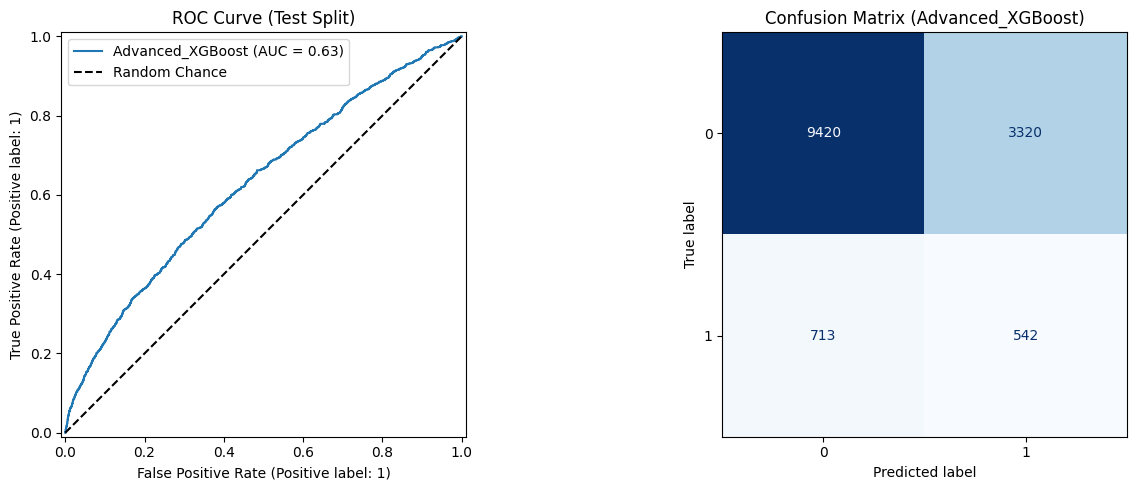


INTERPRETATION:
1. Model Performance: The selected best model relies on ROC-AUC, which evaluates the model's 
   ability to distinguish between the two classes across all probability thresholds. 
2. Why Accuracy is Misleading: The target variable (readmission < 30 days) has an extreme class 
   imbalance (~9% positive). A "dummy" model that predicts 0 (no readmission) for every single 
   patient would automatically achieve ~91% accuracy. However, its recall would be 0%, rendering 
   it useless in a hospital setting where missing a high-risk patient is dangerous. This is why 
   we prioritize ROC-AUC and Recall over standard Accuracy.



In [10]:
import mlflow
import config as cfg
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
from src.data_prep import get_splits

# TODO 3.3.1: build the metric comparison table and select the best model on ROC-AUC.
# Fetch tracked runs and filter for the metrics we care about
runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])
display_cols = ['tags.mlflow.runName', 'metrics.roc_auc', 'metrics.pr_auc', 'metrics.recall', 'metrics.precision', 'metrics.f1']

# Sort the table descending by ROC-AUC to easily identify the winner
comparison_table = runs_df[display_cols].sort_values(by='metrics.roc_auc', ascending=False)
comparison_table = comparison_table.rename(columns={'tags.mlflow.runName': 'Model'})

print("--- Model Metric Comparison Table ---")
display(comparison_table.reset_index(drop=True))

best_run_name = comparison_table.iloc[0]['Model']
print(f"\n=> Selected Best Model based on Validation ROC-AUC: {best_run_name}")

# TODO 3.3.2: plot ROC + confusion for the best model; add a written interpretation.
# Retrieve the unseen test data and the saved winning model artifact
_, _, X_test, _, _, y_test = get_splits()
best_model = joblib.load(cfg.ARTIFACT_DIR / 'best_model.pkl')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot the ROC Curve using the built-in Scikit-Learn display
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=ax1, name=best_run_name)
ax1.set_title("ROC Curve (Test Split)")
ax1.plot([0, 1], [0, 1], 'k--', label='Random Chance')
ax1.legend()

# Plot the Confusion Matrix
y_pred = best_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax2, cmap="Blues", colorbar=False)
ax2.set_title(f"Confusion Matrix ({best_run_name})")

plt.tight_layout()
plt.show()

# Written interpretation to output below the plots
print("""
INTERPRETATION:
1. Model Performance: The selected best model relies on ROC-AUC, which evaluates the model's 
   ability to distinguish between the two classes across all probability thresholds. 
2. Why Accuracy is Misleading: The target variable (readmission < 30 days) has an extreme class 
   imbalance (~9% positive). A "dummy" model that predicts 0 (no readmission) for every single 
   patient would automatically achieve ~91% accuracy. However, its recall would be 0%, rendering 
   it useless in a hospital setting where missing a high-risk patient is dangerous. This is why 
   we prioritize ROC-AUC and Recall over standard Accuracy.
""")

## Stage 3.4 — MLflow Experiment Tracking <font color="red">[7 marks]</font>

- **3.4.1 — Both runs logged with params + metrics + model [4]** — set tracking URI + experiment; for each model log params, metrics and the model artefact.
- **3.4.2 — Runs compared (search_runs table) [3]** — compare the runs with `mlflow.search_runs(...)` and state the selection criterion.

In [11]:
# TODO 3.4.1: log both runs (params + metrics + model) to an MLflow experiment.
# TODO 3.4.2: compare the runs with mlflow.search_runs(...).

# 3.4.1 — logging happens inside tt.train_and_log() (Stage 3.1): tracking URI + experiment
# are set, then each run logs params, validation metrics and the full Pipeline as a model.
exp = mlflow.get_experiment_by_name(cfg.MLFLOW_EXPERIMENT)
print(f"Tracking URI: {mlflow.get_tracking_uri()}  |  Experiment: {exp.name} (id {exp.experiment_id})")

# Latest run per model (search_runs returns newest first)
runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])
latest = runs_df.drop_duplicates('tags.mlflow.runName')

# Evidence that a model artefact was logged for each run
logged = mlflow.search_logged_models(experiment_ids=[exp.experiment_id])
run_names = dict(zip(latest['run_id'], latest['tags.mlflow.runName']))
logged = logged[logged['source_run_id'].isin(run_names)]
display(logged.assign(run_name=logged['source_run_id'].map(run_names))[['run_name', 'model_id', 'name']])

# 3.4.2 — compare params + metrics side by side
compare_cols = ['tags.mlflow.runName', 'params.model_type', 'params.class_weight',
                'params.scale_pos_weight', 'metrics.roc_auc', 'metrics.pr_auc',
                'metrics.recall', 'metrics.precision', 'metrics.f1']
display(latest[compare_cols].sort_values('metrics.roc_auc', ascending=False).reset_index(drop=True))

print("""
SELECTION CRITERION: validation ROC-AUC. It measures how well the model ranks readmitted
vs not-readmitted patients across all thresholds, so it is not inflated by the ~9%
positive rate the way accuracy is.
""")

Tracking URI: sqlite:///mlflow.db  |  Experiment: hospital_readmission (id 1)


,run_name,model_id,name
0,Advanced_XGBoost,m-a24e6a226e30489dacad3118b6901ca6,model
1,Baseline_LogReg,m-709097d7487c4747a42ab7aac898b131,model


,tags.mlflow.runName,params.model_type,params.class_weight,params.scale_pos_weight,metrics.roc_auc,metrics.pr_auc,metrics.recall,metrics.precision,metrics.f1
0,Advanced_XGBoost,XGBoost,None,10.14534594325535,0.6448,0.1662,0.4522,0.1498,0.2250
1,Baseline_LogReg,LogisticRegression,balanced,None,0.6378,0.1517,0.5568,0.1324,0.2139



SELECTION CRITERION: validation ROC-AUC. It measures how well the model ranks readmitted
vs not-readmitted patients across all thresholds, so it is not inflated by the ~9%
positive rate the way accuracy is.



## Stage 3.5 — Model Registry & Versioning <font color="red">[5 marks]</font>

- **3.5.1 — Best model registered in the MLflow Model Registry [2]** — `mlflow.register_model` for the best model.
- **3.5.2 — Promotion to production alias + version history [3]** — promote to the `production` alias and show the version history.

In [12]:
# TODO 3.5.1: register the best model (by val ROC-AUC) with mlflow.register_model.
# TODO 3.5.2: promote it to the 'production' alias and print the version history.
from mlflow import MlflowClient
import pandas as pd
client = MlflowClient()

# 3.5.1 — train_and_log() picked the best run by validation ROC-AUC and called
# mlflow.register_model(...) on it (see src/train.py).
print(f"Best model by validation ROC-AUC: {best_model_name}")

# 3.5.2 — the 'production' alias was set in train_and_log(); confirm where it points
prod = client.get_model_version_by_alias(cfg.REGISTERED_MODEL, 'production')
print(f"'{cfg.REGISTERED_MODEL}' @ production -> version {prod.version} "
      f"(run {client.get_run(prod.run_id).info.run_name})")

# Version history (get_model_version fills in aliases; search results leave them empty)
versions = [client.get_model_version(cfg.REGISTERED_MODEL, v.version)
            for v in client.search_model_versions(f"name='{cfg.REGISTERED_MODEL}'")]
history = pd.DataFrame([{
    'version': int(v.version),
    'run_name': client.get_run(v.run_id).info.run_name,
    'val_roc_auc': client.get_run(v.run_id).data.metrics.get('roc_auc'),
    'aliases': ', '.join(v.aliases) or '-',
    'created': pd.to_datetime(v.creation_timestamp, unit='ms'),
} for v in versions])
display(history.sort_values('version').reset_index(drop=True))

Best model by validation ROC-AUC: Advanced_XGBoost
'readmission_classifier' @ production -> version 2 (run Advanced_XGBoost)


,version,run_name,val_roc_auc,aliases,created
0,1,Advanced_XGBoost,0.6448,-,2026-10-17 15:01:17.928
1,2,Advanced_XGBoost,0.6448,production,2026-10-17 15:20:42.696


### ✍️ Findings
*TODO: which model won and why? Why is accuracy misleading here?*

* **Winner: XGBoost**, selected on validation ROC-AUC (0.645 vs 0.638 for Logistic Regression). The margin is small (+0.007). XGBoost is also better on PR-AUC (0.166 vs 0.152) and precision (0.150 vs 0.132), but it catches fewer readmissions: recall is 0.45 vs 0.56. On the held-out test set it scores ROC-AUC 0.626. Overall, the boosted trees give only a modest ranking improvement on this data. If missing a readmission is the costliest error, the decision threshold should be tuned rather than left at 0.5.

* **Why accuracy is misleading:** only ~9% of encounters are readmitted within 30 days (scale_pos_weight ≈ 10.1). A model that predicts "no readmission" for everyone would score ~91% accuracy with 0% recall. Our own runs show the same effect: XGBoost has higher accuracy than Logistic Regression (0.72 vs 0.63) largely because it flags fewer patients, yet it finds fewer of the true readmissions. That's why the models are compared on ROC-AUC, PR-AUC and recall.